# 05 - Spectrogram EDA and Insights

**Goal:** study the log-mel spectrograms that the CNN will learn from: how emotions differ in the time-frequency plane, which emotions look alike, how much padding there is, and what augmentation to plan.

**Input:** `data/X_logmel_raw.npy`, `data/X_logmel_norm.npy`, `data/labels.csv` (from notebook 04).
**Output:** figures in `images/` (prefix `spec_`) and the written insights at the end.

All class-level statistics use **training clips only**, so the test set is never inspected.

## 0. Imports and load data

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
os.makedirs("../images", exist_ok=True)
os.makedirs("../data", exist_ok=True)

EMOTIONS = ["neutral", "calm", "happy", "sad", "angry", "fearful", "disgust", "surprised"]

import librosa, librosa.display

SR, HOP = 22050, 512
X = np.load("../data/X_logmel_raw.npy")      # dB values, (n_clips, 128, 173)
Xn = np.load("../data/X_logmel_norm.npy")    # normalized
MEAN, STD = np.load("../data/norm_stats.npy")
lab = pd.read_csv("../data/labels.csv")
N, N_MELS, N_FRAMES = X.shape
print("Spectrogram array:", X.shape, "| train mean/std:", round(float(MEAN), 2), round(float(STD), 2))

tr = (lab["split"] == "train").values
valid = np.arange(N_FRAMES)[None, :] < lab["n_valid_frames"].values[:, None]   # True = real audio

Spectrogram array: (1439, 128, 173) | train mean/std: -17.16 15.78


## 1. Dataset shape and class counts per split

In [2]:
print(pd.crosstab(lab["split"], lab["emotion"])[EMOTIONS])
print()
print("Input to the CNN: one-channel image of", (N_MELS, N_FRAMES), "(mel bands x time frames)")

emotion  neutral  calm  happy  sad  angry  fearful  disgust  surprised
split                                                                 
test          20    40     40   40     40       40       40         40
train         60   120    119  120    120      120      120        120
val           16    32     32   32     32       32       32         32

Input to the CNN: one-channel image of (128, 173) (mel bands x time frames)


## 2. How much of each spectrogram is padding?

**Why:** if most of an input is padding, the network wastes capacity on it, and differences in clip length leak into the input shape. Emotions also differ in speaking speed, so padding can differ by emotion.

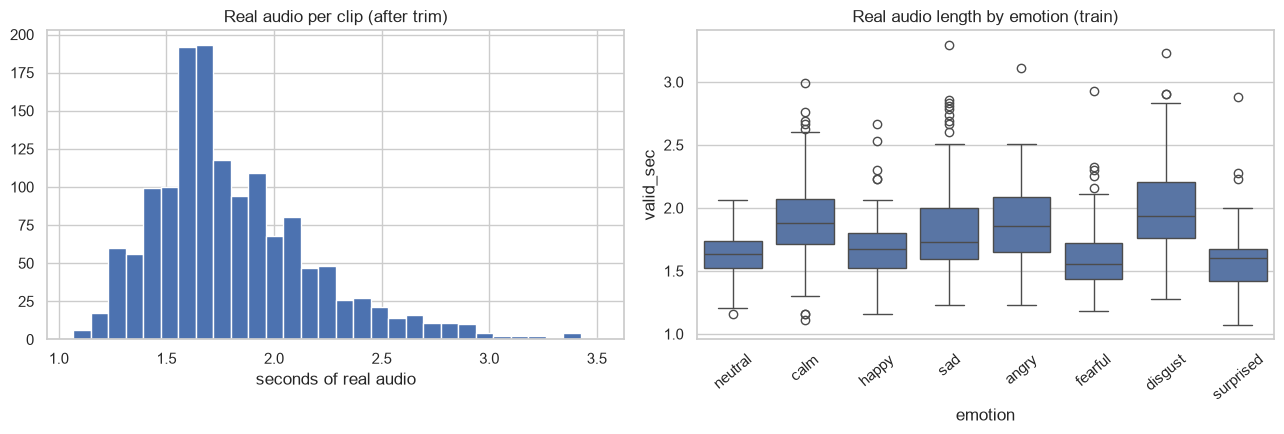

Average share of each spectrogram that is padding: 55%


In [3]:
lab["valid_sec"] = lab["n_valid_frames"] * HOP / SR
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(lab["valid_sec"], bins=30, color="#4C72B0")
axes[0].set_xlabel("seconds of real audio"); axes[0].set_title("Real audio per clip (after trim)")
sns.boxplot(data=lab[lab["split"] == "train"], x="emotion", y="valid_sec", order=EMOTIONS, ax=axes[1])
axes[1].set_title("Real audio length by emotion (train)"); axes[1].tick_params(axis="x", rotation=40)
plt.tight_layout()
plt.savefig("../images/spec_valid_length.png", dpi=140)
plt.show()
print("Average share of each spectrogram that is padding: %.0f%%" % (100 * (1 - valid.mean())))

**What it shows:** the typical clip fills only part of the 4 s window and the rest is padding. This is why padding uses the silence floor (not 0) and why the normalization statistics ignore padded frames.

## 3. Average spectrogram per emotion

**Why:** shows the typical time-frequency pattern of each emotion. If the averages look clearly different, a CNN has signal to learn from.

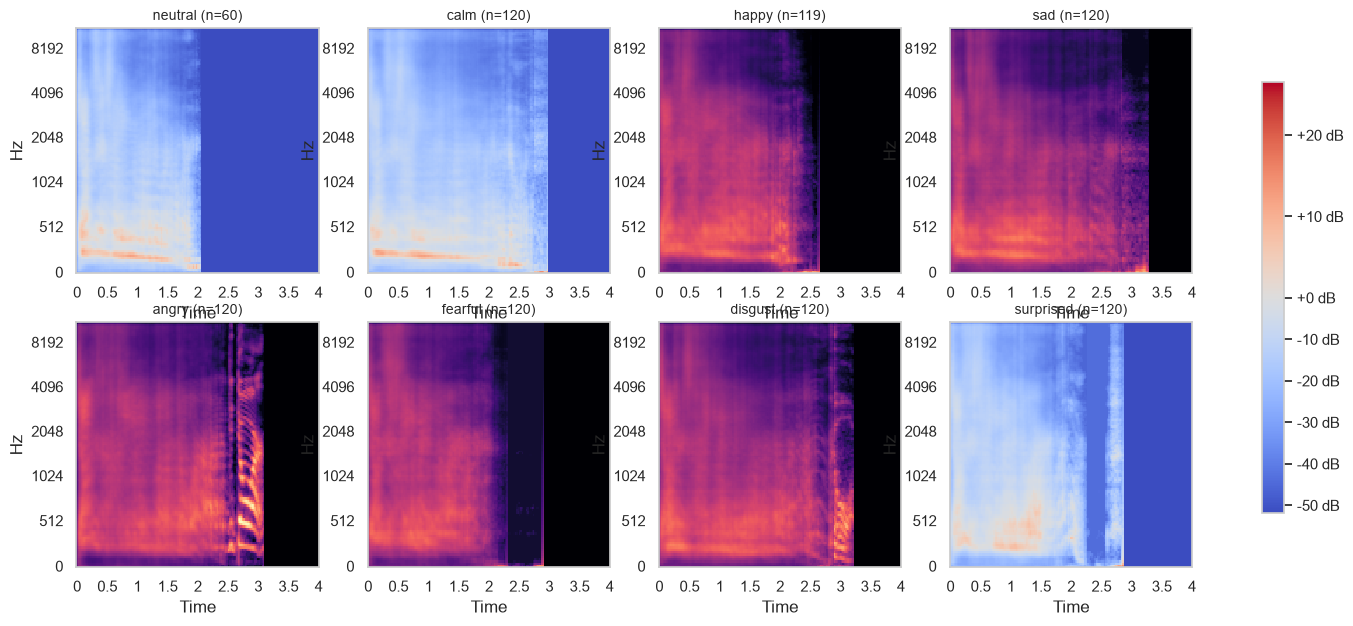

In [4]:
def mean_spec(idx):
    """Mean spectrogram over clips idx, averaging only frames that contain real audio."""
    m = valid[idx][:, None, :]
    s = (X[idx] * m).sum(axis=0)
    c = m.sum(axis=0)
    return np.where(c > 0, s / np.maximum(c, 1), np.nan)

emo_idx = {e: np.where(tr & (lab["emotion"] == e).values)[0] for e in EMOTIONS}

means = {e: mean_spec(emo_idx[e]) for e in EMOTIONS}
vmin = np.nanmin([m for m in means.values()]); vmax = np.nanmax([m for m in means.values()])

fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, e in zip(axes.ravel(), EMOTIONS):
    img = librosa.display.specshow(np.nan_to_num(means[e], nan=vmin), sr=SR, hop_length=HOP,
                                   x_axis="time", y_axis="mel", ax=ax, vmin=vmin, vmax=vmax)
    ax.set_title(f"{e} (n={len(emo_idx[e])})", fontsize=10)
fig.colorbar(img, ax=axes, format="%+2.0f dB", shrink=0.8)
plt.savefig("../images/spec_mean_per_emotion.png", dpi=140, bbox_inches="tight")
plt.show()

**What it shows:** all emotions share the same overall shape (energy concentrated at low frequencies), so differences are subtle: how far energy extends to high frequencies, how loud the mid bands are, and how long the speech lasts. The next plots make these differences visible.

## 4. Difference maps for easily confused emotion pairs

**Why:** subtracting two average spectrograms shows *where* they differ (red = first emotion has more energy, blue = second has more). Pairs that are acoustically close are the ones the CNN will confuse.

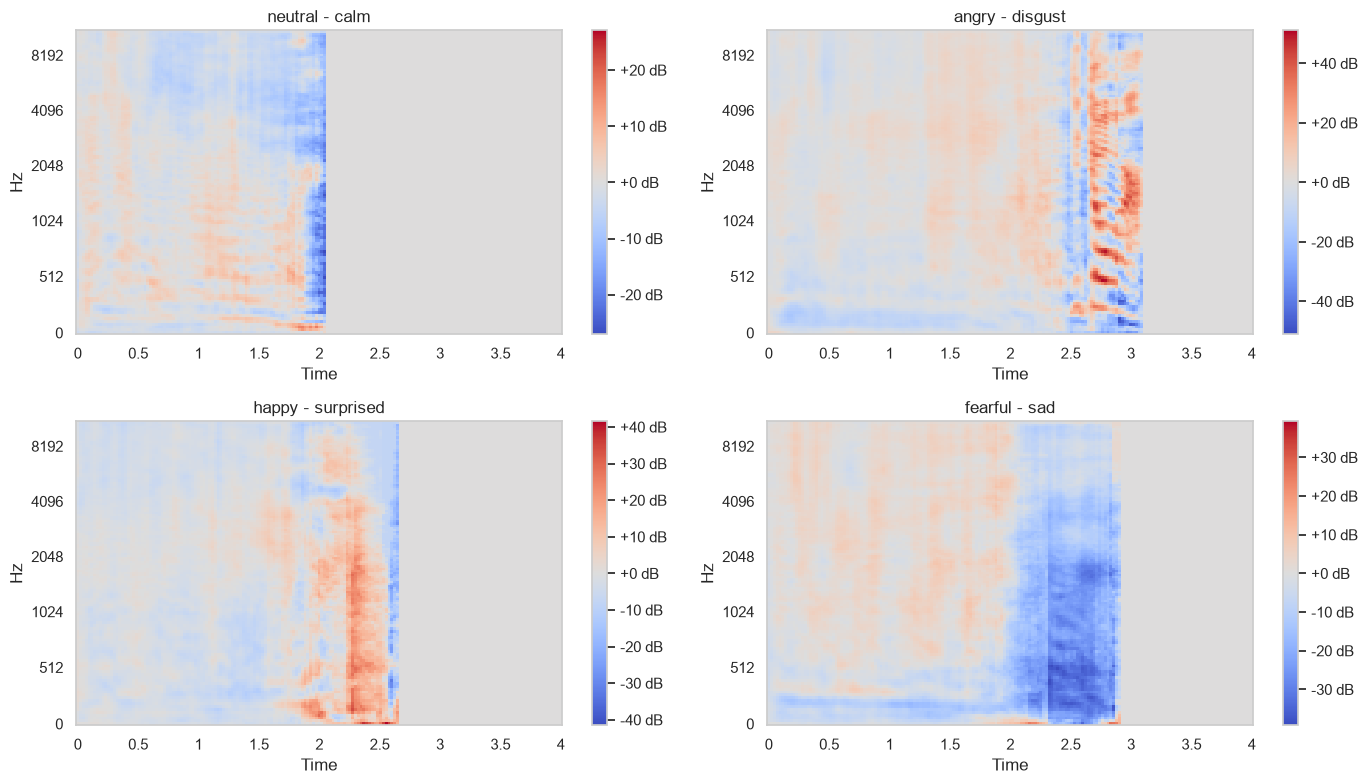

In [5]:
pairs = [("neutral", "calm"), ("angry", "disgust"), ("happy", "surprised"), ("fearful", "sad")]
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, (a, b) in zip(axes.ravel(), pairs):
    d = np.nan_to_num(means[a] - means[b], nan=0.0)
    lim = np.abs(d).max() + 1e-9
    img = librosa.display.specshow(d, sr=SR, hop_length=HOP, x_axis="time", y_axis="mel",
                                   ax=ax, cmap="coolwarm", vmin=-lim, vmax=lim)
    ax.set_title(f"{a} - {b}")
    fig.colorbar(img, ax=ax, format="%+2.0f dB")
plt.tight_layout()
plt.savefig("../images/spec_difference_pairs.png", dpi=140)
plt.show()

**What it shows:** the weaker and more uniform the colors, the more alike a pair is. Pairs with small differences (for example neutral vs calm) are expected to be the hardest for the CNN, and Phase 2 will check this against the confusion matrix.

## 5. Frequency profile and overall level by emotion

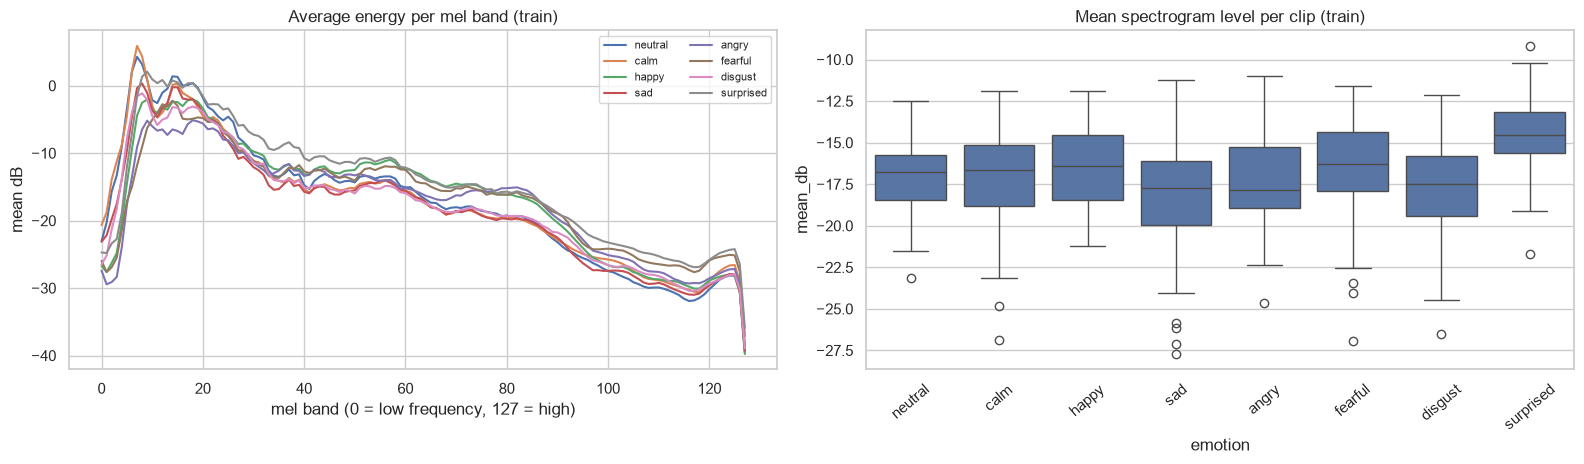

In [6]:
v = valid[:, None, :]
clip_band = (X * v).sum(axis=2) / np.maximum(valid.sum(axis=1)[:, None], 1)   # (n_clips, 128) mean dB per band
clip_level = clip_band.mean(axis=1)                                          # mean dB per clip
lab["mean_db"] = clip_level

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
for e in EMOTIONS:
    axes[0].plot(clip_band[emo_idx[e]].mean(axis=0), label=e)
axes[0].set_xlabel("mel band (0 = low frequency, 127 = high)"); axes[0].set_ylabel("mean dB")
axes[0].set_title("Average energy per mel band (train)"); axes[0].legend(fontsize=8, ncol=2)
sns.boxplot(data=lab[lab["split"] == "train"], x="emotion", y="mean_db", order=EMOTIONS, ax=axes[1])
axes[1].set_title("Mean spectrogram level per clip (train)"); axes[1].tick_params(axis="x", rotation=40)
plt.tight_layout()
plt.savefig("../images/spec_band_profiles.png", dpi=140)
plt.show()

**What it shows:** the lines are close together at low frequencies and separate at higher bands, so the high-frequency region carries a good part of the emotion information. The overall level boxplot shows the spread within each emotion.

## 6. Which emotions look alike? Correlation of spectral profiles

**Why:** a quick, model-free hint about likely confusions. Each emotion's average band profile has the shared speech shape removed (we subtract the average of all emotions) and is then correlated with the others. A high value means the two emotions deviate from the average in the same way.

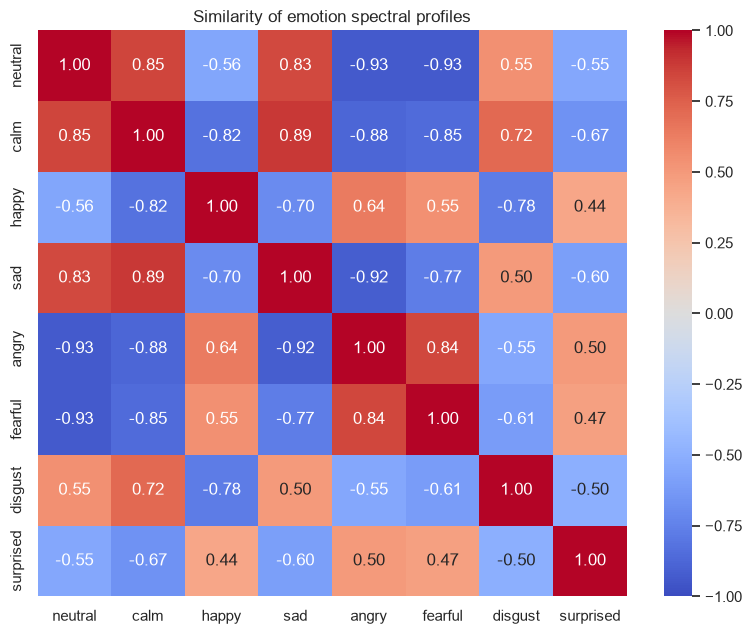

Most similar pairs:
  calm / sad: +0.89
  neutral / calm: +0.85
  angry / fearful: +0.84
  neutral / sad: +0.83
  calm / disgust: +0.72


In [7]:
profiles = np.stack([clip_band[emo_idx[e]].mean(axis=0) for e in EMOTIONS])    # (8, 128)
dev = profiles - profiles.mean(axis=0, keepdims=True)
corr = np.corrcoef(dev)

plt.figure(figsize=(8, 6.5))
sns.heatmap(pd.DataFrame(corr, index=EMOTIONS, columns=EMOTIONS), annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Similarity of emotion spectral profiles")
plt.tight_layout()
plt.savefig("../images/spec_emotion_similarity.png", dpi=140)
plt.show()

pairs_sim = [(EMOTIONS[i], EMOTIONS[j], corr[i, j]) for i in range(8) for j in range(i + 1, 8)]
print("Most similar pairs:")
for a, b, c in sorted(pairs_sim, key=lambda t: -t[2])[:5]:
    print(f"  {a} / {b}: {c:+.2f}")

**What it shows:** emotion pairs with a high positive correlation have similar spectral shape and are the most likely to be confused. This is a hint only, not a result: the real answer comes from the confusion matrix in Phase 2.

## 7. Planned augmentation (SpecAugment preview)

**Why:** there are only about 900 training clips, so a CNN will overfit quickly. SpecAugment hides random frequency bands and time steps so the network cannot rely on any single region. It is applied **only to training data**, during training. This is a preview; the real augmentation is added in Phase 2.

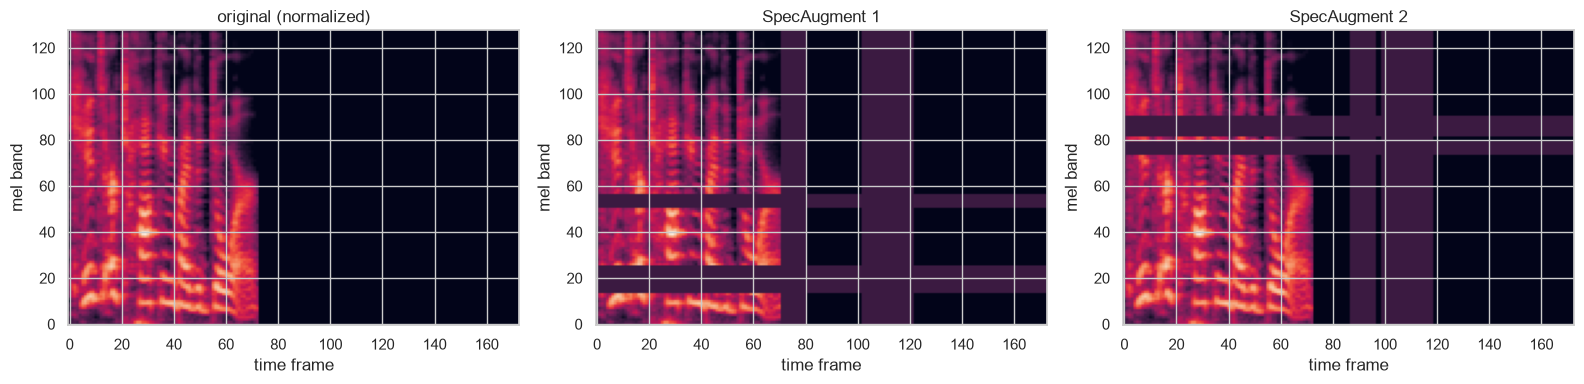

In [8]:
def spec_augment(S, rng, n_freq=2, max_f=15, n_time=2, max_t=20):
    S = S.copy()
    fill = S.mean()
    for _ in range(n_freq):
        f = rng.randint(0, max_f + 1); f0 = rng.randint(0, S.shape[0] - f + 1)
        S[f0:f0 + f, :] = fill
    for _ in range(n_time):
        t = rng.randint(0, max_t + 1); t0 = rng.randint(0, S.shape[1] - t + 1)
        S[:, t0:t0 + t] = fill
    return S

rng = np.random.RandomState(42)
i = emo_idx["angry"][0]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].imshow(Xn[i], origin="lower", aspect="auto"); axes[0].set_title("original (normalized)")
for ax, k in zip(axes[1:], range(2)):
    ax.imshow(spec_augment(Xn[i], rng), origin="lower", aspect="auto"); ax.set_title(f"SpecAugment {k + 1}")
for ax in axes:
    ax.set_xlabel("time frame"); ax.set_ylabel("mel band")
plt.tight_layout()
plt.savefig("../images/spec_augment_demo.png", dpi=140)
plt.show()

The masked stripes (horizontal = frequency masks, vertical = time masks) show the kind of variation the CNN will train on.

## 8. Insights (what we learned and what it means for modeling)

**Dataset and split**
- About 1,440 clips (24 actors x 60). Train = 15 actors (about 900 clips), validation = 4 actors (about 240), test = 5 actors (about 300), all **speaker-independent**.
- **Small dataset:** about 900 training clips for a CNN means overfitting is the main risk. Plan SpecAugment, noise / time-shift augmentation, dropout, weight decay and early stopping on the validation actors.
- **Class imbalance:** neutral has about half as many clips as every other class (about 7% vs 13%). Use a weighted loss and report **macro** precision, recall and F1, not only accuracy.
- **Test set limitation:** 4 male actors and 1 female actor, so results mostly reflect male voices. State this in the final report.

**What the audio tells us**
- Only two sentences are spoken, so the words carry no emotion information. The model must learn delivery (pitch, energy, timing).
- Emotions differ in speaking speed, loudness and spectral energy distribution, but the differences are subtle compared to speaker differences, which supports the speaker-independent evaluation.
- Likely confusion pairs, to check against the confusion matrix in Phase 2: neutral / calm, fearful / sad, angry / disgust, happy / surprised (see sections 4 and 6).

**Preprocessing decisions**
- Fixed input of 128 mel bands x 173 frames (4 s). Most clips contain padding, filled with the silence floor and excluded from the normalization statistics.
- Peak normalization removes absolute loudness; log-mel dB values keep relative energy within a clip.
- Normalization uses the **training mean and standard deviation only** (no leakage into validation or test).
- Outlier clips found in the cleaning step were **kept** because they are natural emotional variation.

**Next (Phase 2):** build the CNN (3-4 conv blocks, BatchNorm, dropout, weighted loss), tune learning rate / dropout / augmentation on the validation actors, evaluate once on the test actors, and compare with the SVM and Random Forest using accuracy, macro precision / recall / F1 and confusion matrices.